# Backward Shift Operator

The backward shift operator $B$ is defined by $BX_t = X_{t-1}$, so $B^kX_t=X_{t-k}$. Polynomials in $B$ package lagged equations, differences and ARMA models compactly. This notebook expands operator expressions numerically, checks them against array shifts, and verifies that the inverse $(1-\phi B)^{-1}$ is a geometric series.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(40)

def shift(x, k=1):
    """Apply B^k to an array; the first k entries are undefined (NaN)."""
    out = np.full(len(x), np.nan)
    out[k:] = x[:len(x) - k]
    return out

y = np.array([8., 10., 13., 12., 15.])
print("y      :", y)
print("B y    :", shift(y))
print("(1-B)y :", y - shift(y))
print("(1-B)^2 y:", y - 2 * shift(y) + shift(y, 2))

y      : [ 8. 10. 13. 12. 15.]
B y    : [nan  8. 10. 13. 12.]
(1-B)y : [nan  2.  3. -1.  3.]
(1-B)^2 y: [nan nan  1. -4.  4.]


The last entries reproduce the worked example in the note: $(1-B)y_5=15-12=3$ and $(1-B)^2y_5=15-24+13=4$. The first $k$ values of a $k$-fold shift are undefined, which is why differencing shortens a sample.

In [2]:
# (1-B)^d via binomial coefficients agrees with repeated np.diff
from math import comb
def diff_operator(x, d):
    w = np.array([(-1) ** j * comb(d, j) for j in range(d + 1)])
    return np.convolve(x, w)[d:len(x)]   # keep only fully observed values

x = rng.normal(size=12).cumsum()
for d in (1, 2, 3):
    print(d, np.allclose(diff_operator(x, d), np.diff(x, n=d)))

1 True
2 True
3 True


## Combining ordinary and seasonal differences

Operators multiply like ordinary polynomials: $(1-B)(1-B^{12})=1-B-B^{12}+B^{13}$. Applying the product at once must equal applying the two differences one after the other.

lengths: 47 47
same values: True


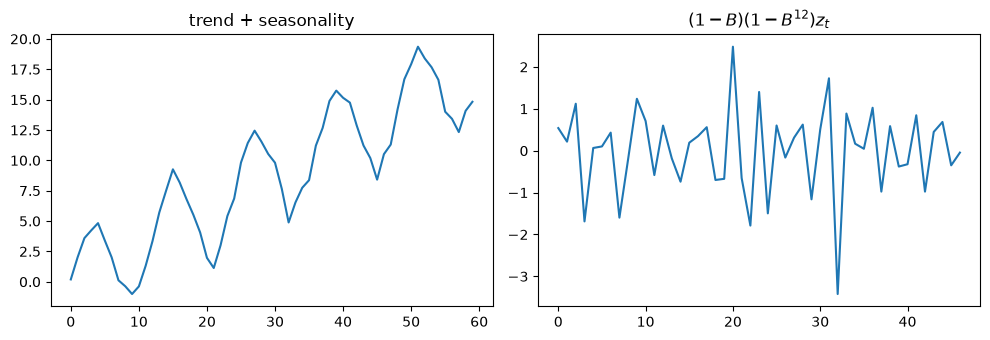

In [3]:
n, s = 60, 12
t = np.arange(n)
z = 0.3 * t + 4 * np.sin(2 * np.pi * t / s) + rng.normal(scale=0.5, size=n)

two_step = np.diff(z[s:] - z[:-s])
direct = z[s + 1:] - z[s:-1] - z[1:-s] + z[:-s - 1]   # z_t - z_{t-1} - z_{t-12} + z_{t-13}
print("lengths:", len(two_step), len(direct))
print("same values:", np.allclose(two_step, direct))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(z); ax[0].set_title("trend + seasonality")
ax[1].plot(two_step); ax[1].set_title(r"$(1-B)(1-B^{12})z_t$")
plt.tight_layout(); plt.show()

## The inverse operator

For $|\phi|<1$, $(1-\phi B)^{-1}=\sum_j\phi^jB^j$. Solving $(1-\phi B)X_t=Z_t$ by the recursion $X_t=\phi X_{t-1}+Z_t$ and by the truncated sum $\sum_{j<J}\phi^jZ_{t-j}$ should agree except for a vanishing truncation error.

In [4]:
phi, n, J = 0.8, 300, 40
Z = rng.normal(size=n)

X = np.zeros(n)
for t in range(1, n):
    X[t] = phi * X[t - 1] + Z[t]

weights = phi ** np.arange(J)
trunc = np.array([weights[:min(J, t + 1)] @ Z[t::-1][:min(J, t + 1)] for t in range(n)])
err = np.abs(X - trunc)[100:]
print("max |recursion - truncated sum| after burn-in:", err.max())
print("neglected weight phi^J =", phi ** J)

max |recursion - truncated sum| after burn-in: 0.0006300513996917445
neglected weight phi^J = 0.00013292279957849188


The agreement is limited only by the neglected weight $\phi^{J}$ (and the initial condition), which is the sense in which the operator inverse "exists" for $|\phi|<1$. For $\phi=1$ the weights never decay and $(1-B)$ has no stable inverse, which is why random walks must be differenced rather than inverted.